# 5.2 Short braced columns: B2 (internal) and B1 (edge)

| Step | Check | Reference |
|:--|:--|:--|
| 1 | N, M from Notebook 5.1 | EN 1990 |
| 2 | Cover, bars, limits, links, fire | EC2 4.4.1, 9.5; EN 1992-1-2 5.3 |
| 3 | Effective length, imperfection, slenderness | EC2 5.2, 5.8.3 |
| 4 | Interaction diagram from strain compatibility | EC2 6.1, 3.1.7, 3.2.7 |
| 5 | Second-order moment if λ > λ<sub>lim</sub>; biaxial check | EC2 5.8.8, 5.8.9 |
| 6 | Minimum axial load case for edge columns | EN 1990 |

In [1]:
import sys; sys.path.insert(0, '..')
from ec2.setup import *

The columns are sized as short. If a direction turns out slender, the sheet adds second-order effects automatically (method in 5.3).

## The interaction diagram

For each neutral-axis depth x, strains follow EC2 Fig. 6.1: 3.5‰ at the edge for x ≤ h; pivot at 2.0‰ at 3h/7 for x > h, down to uniform 2.0‰.
The concrete force is the rectangular block (0.8x, f<sub>cd</sub>); each bar stress is E<sub>s</sub>ε ≤ f<sub>yd</sub>; concrete displaced by compression bars is deducted.
$$N = f_{cd}b\,(0.8x) + \sum A_{si}\sigma_{si}, \qquad M = f_{cd}b(0.8x)\left(\tfrac h2-0.4x\right)+\sum A_{si}\sigma_{si}\left(\tfrac h2-y_i\right)$$

### Input guide

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `phi` | Main bar; 8 bars, fixed layout | mm | 12, 16, 20, 25, 32 |
| `link`, `s_link` | Link size and spacing | mm |  |

Column size, loads and materials come from `BRIEF`: see the guide in Notebook 0.1. Keep the column square.

In [2]:
# INPUTS: edit only this cell, then run the cells below it
# Size, loads and materials come from BRIEF in ec2/project.py. Layout: 8 bars (4 corners, 4 mid-faces)
phi, link, s_link = 16, 8, 300      # main bar (mm), link (mm), link spacing (mm)

In [3]:
def direction(s, axis, N, M, kb_sum, b, h, As, qp):
    """Design moment in one direction (first order, plus second order if slender). qp = quasi-permanent / ULS load ratio."""
    s.let("M_top", M, "kN·m", f"First-order moment at the top, {axis}", "BS 8110-1 3.2.1.2.5")
    s.let("k_c", b * h**3 / 12 / (BRIEF["storey"] * 1e3) / 1e3, "10³ mm³", "I/l of each column"); s.let("k_b", kb_sum, "10³ mm³", "Sum of I/l of the beams (rectangular gross section, conservative)")
    s.calc("k1", "max(2*k_c/(2*k_b), 0.1)", "", "EC2 5.8.3.2(3), (4)", "Top: columns above and below, beams at 2EI/l")
    s.let("l", BRIEF["storey"] - BRIEF["beam"][1] / 1000, "m", "Clear height")
    s.calc("l0", "0.5*l*sqrt((1 + k1/(0.45 + k1))*2)", "m", "EC2 Exp. (5.15), k₂ = ∞", "Base taken as pinned (upper bound: the bracket tends to 2)")
    s.let("N_Ed", N, "kN"); s.let("h", h, "mm"); s.let("b", b, "mm")
    C.imperfection(s)
    s.calc("M_02", "M_top + N_Ed*e_i/1000", "kN·m", "EC2 5.2(7)", "Larger end, with imperfection"); s.calc("M_01", "N_Ed*e_i/1000", "kN·m", "EC2 5.2(7)", "Smaller end: pinned base, imperfection only")
    slender = C.slenderness(s, s["l"], h, N, b, s["M_01"], s["M_02"], l0=s["l0"], As=As)
    if slender:
        C.creep(s, b, h, BRIEF["RH"], BRIEF["t0"])
        s.let("i_s", math.sqrt(6 * (h / 2 - s["d_c"]) ** 2 / 8), "mm", "Radius of gyration of the 8 bars", "EC2 5.8.8.3(2)"); s.calc("d", "h/2 + i_s", "mm", "EC2 5.8.8.3(2)")
        C.second_order(s, s["d"], qp)
        s.calc("M_Ed", "max(M_02, M_0e + M_2, M_01 + 0.5*M_2, M_min)", "kN·m", "EC2 5.8.8.2, 6.1(4); BS 8110-1 3.8.3.2", f"Design moment with second-order effects, {axis}")
    else:
        s.calc("M_Ed", "max(M_02, M_min)", "kN·m", "EC2 5.8.8.1, 6.1(4)", f"Design moment, {axis}")
    return s["M_Ed"]

b, h = BRIEF["col"]
I_b = BRIEF["beam"][0] * BRIEF["beam"][1] ** 3 / 12 / 1e3          # 10^3 mm3 x mm
kbeam = lambda ln: I_b / ((BRIEF["lx_bay"] if ln in "AB" else BRIEF["ly_bay"]) * 1e3)

def section(s, N):
    """Cover, bars, limits, links, interaction curve for the 8-bar column."""
    c = D.cover(s, BRIEF["exposure"], phi, link)
    s.let("N_Ed", N, "kN"); s.let("A_c", b * h, "mm²"); s.let("phi_min", BRIEF["ndp"]["phi_col_min"], "mm", "Minimum bar", "EC2 9.5.2(1), NA"); s.check("phi", ">=", "phi_min", "minimum bar diameter", "EC2 9.5.2(1)")
    s.calc("A_s_min", "max(0.10*N_Ed*1000/f_yd, 0.002*A_c)", "mm²", "EC2 Exp. (9.12N)"); s.calc("A_s_max", "0.04*A_c", "mm²", "EC2 9.5.2(3)")
    s.calc("A_s", "8*pi*phi**2/4", "mm²", "", f"8H{phi}: one at each corner, one at the middle of each face"); s.check("A_s", ">=", "A_s_min", "minimum steel", "EC2 9.5.2(2)"); s.check("A_s", "<=", "A_s_max", "maximum steel", "EC2 9.5.2(3)")
    s.calc("d_c", "c_nom + phi_link + phi/2", "mm", "", "Bar centre from the face"); s.show("Reinforcement")
    C.links(s, phi, phi, b, h, link, s_link, 3, 3, c); s.show("Links")
    cur = C.interaction(b, h, C.perimeter_layers(3, 3, phi, b, h, s["d_c"]), s["f_cd"], s["f_yd"])
    return c, cur

## Column B2 (internal)

## Column B2

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Column B2, ground storey

### Materials

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 Table 3.1 | Concrete cylinder strength (project input): $f_{ck}$ | $f_{ck} = 30$ N/mm²<br><small>(= 30 MPa)</small> |
| EC2 3.2.2(3) | Steel yield strength (project input): $f_{yk}$ | $f_{yk} = 500$ N/mm²<br><small>(= 500 MPa)</small> |
| EC2 2.4.2.4, Table 2.1N | Partial factor, concrete: $\gamma_{c}$ | $\gamma_{c} = 1.5$  |
| EC2 2.4.2.4, Table 2.1N | Partial factor, reinforcement: $\gamma_{s}$ | $\gamma_{s} = 1.15$  |
| EC2 3.1.6(1), NA | Flexure and axial load (UK National Annex): $\alpha_{cc}$ | $\alpha_{cc} = 0.85$  |
| EC2 Exp. (3.15) | $f_{cd} = \dfrac{\alpha_{cc}\,f_{ck}}{\gamma_{c}}$<br>$\quad = \dfrac{0.85\times 30}{1.5}$ | $\mathbf{f_{cd} = 17}$ N/mm²<br><small>(= 17 MPa)</small> |
| EC2 3.2.7, Fig. 3.8 | $f_{yd} = \dfrac{f_{yk}}{\gamma_{s}}$<br>$\quad = \dfrac{500}{1.15}$ | $\mathbf{f_{yd} = 434.8}$ N/mm²<br><small>(= 434.8 MPa)</small> |
| EC2 Table 3.1 | $f_{ctm} = 0.3\,f_{ck}^{2/3}$<br>$\quad = 0.3\times 30^{2/3}$ | $\mathbf{f_{ctm} = 2.896}$ N/mm²<br><small>(= 2.896 MPa)</small> |
| EC2 3.2.7(4) | Steel modulus: $E_{s}$ | $E_{s} = 200000$ N/mm²<br><small>(= 200000 MPa)</small> |


### Durability – nominal cover

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Main bar diameter: $\phi$ | $\phi = 16$ mm |
| EC2 Table 4.1, 4.4N | Exposure XC1, class S4: $c_{min,dur}$ | $c_{min,dur} = 15$ mm |
| EC2 4.4.1.3(1) | Allowance for deviation: $\Delta c_{dev}$ | $\Delta c_{dev} = 10$ mm |
|  | Link diameter: $\phi_{link}$ | $\phi_{link} = 8$ mm |
| EC2 Exp. (4.1), (4.2) | To the link<br>$c_{nom,link} = \max\left\{\phi_{link};\; c_{min,dur};\; 10\right\} + \Delta c_{dev}$<br>$\quad = \max\left\{8;\; 15;\; 10\right\} + 10$ | $\mathbf{c_{nom,link} = 25}$ mm |
| EC2 Exp. (4.1), (4.2) | To the link, so that the main bar complies<br>$c_{nom,bar} = \max\left\{\phi;\; c_{min,dur};\; 10\right\} + \Delta c_{dev} - \phi_{link}$<br>$\quad = \max\left\{16;\; 15;\; 10\right\} + 10 - 8$ | $\mathbf{c_{nom,bar} = 18}$ mm |
|  | $c_{req} = \max\left\{c_{nom,link};\; c_{nom,bar}\right\}$<br>$\quad = \max\left\{25;\; 18\right\}$ | $\mathbf{c_{req} = 25}$ mm |
|  | Cover adopted: $c_{nom}$ | $c_{nom} = 25$ mm |
| EC2 4.4.1 | **Check:** nominal cover<br>$c_{nom} = 25 \ge c_{req} = 25$ mm | ✅ **PASS**<br>ratio 1.00 |
| NA to EC2, 4.4.1.2(5) | UK projects: confirm concrete quality and cover against BS 8500-1 Tables A.4/A.5 as the UK NA requires. |  |


### Reinforcement

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $N_{Ed}$ | $N_{Ed} = 1674.2$ kN |
|  | $A_{c}$ | $A_{c} = 122500$ mm² |
| EC2 9.5.2(1), NA | Minimum bar: $\phi_{min}$ | $\phi_{min} = 12$ mm |
| EC2 9.5.2(1) | **Check:** minimum bar diameter<br>$\phi = 16 \ge \phi_{min} = 12$ mm | ✅ **PASS**<br>ratio 0.75 |
| EC2 Exp. (9.12N) | $A_{s,min} = \max\left\{\dfrac{0.1\,N_{Ed}\times 1000}{f_{yd}};\; 0.002\,A_{c}\right\}$<br>$\quad = \max\left\{\dfrac{0.1\times 1674.2\times 1000}{434.8};\; 0.002\times 122500\right\}$ | $\mathbf{A_{s,min} = 385.1}$ mm² |
| EC2 9.5.2(3) | $A_{s,max} = 0.04\,A_{c}$<br>$\quad = 0.04\times 122500$ | $\mathbf{A_{s,max} = 4900}$ mm² |
|  | 8H16: one at each corner, one at the middle of each face<br>$A_{s} = \dfrac{8\,\pi\,\phi^{2}}{4}$<br>$\quad = \dfrac{8\times \pi\times 16^{2}}{4}$ | $\mathbf{A_{s} = 1608.5}$ mm² |
| EC2 9.5.2(2) | **Check:** minimum steel<br>$A_{s} = 1608.5 \ge A_{s,min} = 385.1$ mm² | ✅ **PASS**<br>ratio 0.24 |
| EC2 9.5.2(3) | **Check:** maximum steel<br>$A_{s} = 1608.5 \le A_{s,max} = 4900$ mm² | ✅ **PASS**<br>ratio 0.33 |
|  | Bar centre from the face<br>$d_{c} = c_{nom} + \phi_{link} + \dfrac{\phi}{2}$<br>$\quad = 25 + 8 + \dfrac{16}{2}$ | $\mathbf{d_{c} = 41}$ mm |


### Links

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 9.5.3(1) | $\phi_{link,min} = \max\left\{6;\; \dfrac{16}{4}\right\}$<br>$\quad = \max\left\{6;\; \dfrac{16}{4}\right\}$ | $\mathbf{\phi_{link,min} = 6}$ mm |
| EC2 9.5.3(1) | **Check:** link diameter<br>$\phi_{link} = 8 \ge \phi_{link,min} = 6$ mm | ✅ **PASS**<br>ratio 0.75 |
| EC2 9.5.3(3), NA | min(20 φ_min, smaller side, 400): $s_{cl,max}$ | $s_{cl,max} = 320$ mm |
|  | Link spacing: $s_{link}$ | $s_{link} = 300$ mm |
| EC2 9.5.3(3) | **Check:** link spacing<br>$s_{link} = 300 \le s_{cl,max} = 320$ mm | ✅ **PASS**<br>ratio 0.94 |
| EC2 9.5.3(4) | Within 350 mm above/below a beam or slab, and at laps of bars > 14 mm<br>$s_{cl,red} = 0.6\,s_{cl,max}$<br>$\quad = 0.6\times 320$ | $\mathbf{s_{cl,red} = 192}$ mm |
|  | **PROVIDE: H8 links @ 300 mm; @ 175 mm near beams, slabs and laps** | 🟦 **H8 links @ 300 mm; @ 175 mm near beams, slabs and laps** |
|  | Distance from an intermediate bar to the restrained corner bar (centres): $s_{face}$ | $s_{face} = 134$ mm |
| EC2 9.5.3(6) | **Check:** bar within 150 mm of a restrained bar, else add cross-ties<br>$s_{face} = 134 \le 150$ mm | ✅ **PASS**<br>ratio 0.89 |


### Direction x (Beam B)

| Reference | Calculation | Output |
|:--|:--|:--|
| BS 8110-1 3.2.1.2.5 | First-order moment at the top, bending with Beam B: $M_{top}$ | $M_{top} = 14.94$ kN·m |
|  | I/l of each column: $k_{c}$ | $k_{c} = 357.3$ 10³ mm³ |
|  | Sum of I/l of the beams (rectangular gross section, conservative): $k_{b}$ | $k_{b} = 1041.7$ 10³ mm³ |
| EC2 5.8.3.2(3), (4) | Top: columns above and below, beams at 2EI/l<br>$k_{1} = \max\left\{\dfrac{2\,k_{c}}{2\,k_{b}};\; 0.1\right\}$<br>$\quad = \max\left\{\dfrac{2\times 357.3}{2\times 1041.7};\; 0.1\right\}$ | $\mathbf{k_{1} = 0.343}$ |
|  | Clear height: $l$ | $l = 3$ m |
| EC2 Exp. (5.15), k₂ = ∞ | Base taken as pinned (upper bound: the bracket tends to 2)<br>$l_{0} = 0.5\,l\,\sqrt{\left(1 + \dfrac{k_{1}}{0.45 + k_{1}}\right)\times 2}$<br>$\quad = 0.5\times 3\times \sqrt{\left(1 + \dfrac{0.343}{0.45 + 0.343}\right)\times 2}$ | $\mathbf{l_{0} = 2.539}$ m |
|  | $h$ | $h = 350$ mm |
|  | $b$ | $b = 350$ mm |
| EC2 5.2(7), 5.2(9) – braced | Imperfection eccentricity<br>$e_{i} = \dfrac{l_{0}\times 1000}{400}$<br>$\quad = \dfrac{2.539\times 1000}{400}$ | $\mathbf{e_{i} = 6.347}$ mm |
| EC2 6.1(4) | Minimum eccentricity<br>$e_{0} = \max\left\{\dfrac{h}{30};\; 20\right\}$<br>$\quad = \max\left\{\dfrac{350}{30};\; 20\right\}$ | $\mathbf{e_{0} = 20}$ mm |
| EC2 6.1(4) | $M_{min} = \dfrac{N_{Ed}\,e_{0}}{1000}$<br>$\quad = \dfrac{1674.2\times 20}{1000}$ | $\mathbf{M_{min} = 33.48}$ kN·m |
| EC2 5.2(7) | Larger end, with imperfection<br>$M_{02} = M_{top} + \dfrac{N_{Ed}\,e_{i}}{1000}$<br>$\quad = 14.94 + \dfrac{1674.2\times 6.347}{1000}$ | $\mathbf{M_{02} = 25.57}$ kN·m |
| EC2 5.2(7) | Smaller end: pinned base, imperfection only<br>$M_{01} = \dfrac{N_{Ed}\,e_{i}}{1000}$<br>$\quad = \dfrac{1674.2\times 6.347}{1000}$ | $\mathbf{M_{01} = 10.63}$ kN·m |
| EC2 5.8.3.2(1) | Radius of gyration, rectangle<br>$i = \dfrac{h}{\sqrt{12}}$<br>$\quad = \dfrac{350}{\sqrt{12}}$ | $\mathbf{i = 101}$ mm |
| EC2 Exp. (5.14) | $\lambda = \dfrac{l_{0}\times 1000}{i}$<br>$\quad = \dfrac{2.539\times 1000}{101}$ | $\mathbf{\lambda = 25.13}$ |
| EC2 5.8.3.1 | $n = \dfrac{N_{Ed}\times 1000}{b\,h\,f_{cd}}$<br>$\quad = \dfrac{1674.2\times 1000}{350\times 350\times 17}$ | $\mathbf{n = 0.804}$ |
| EC2 5.8.3.1(1) | Creep ratio not used: default: $A$ | $A = 0.7$  |
| EC2 5.8.3.1(1) | $\omega = \dfrac{A_{s}\,f_{yd}}{b\,h\,f_{cd}}$<br>$\quad = \dfrac{1608.5\times 434.8}{350\times 350\times 17}$ | $\mathbf{\omega = 0.336}$ |
| EC2 5.8.3.1(1) | $B = \sqrt{1 + 2\,\omega}$<br>$\quad = \sqrt{1 + 2\times 0.336}$ | $\mathbf{B = 1.293}$ |
| EC2 5.8.3.1(1) | $r_{m} = \dfrac{M_{01}}{M_{02}}$<br>$\quad = \dfrac{10.63}{25.57}$ | $\mathbf{r_{m} = 0.416}$ |
| EC2 5.8.3.1(1) | $C = 1.7 - r_{m}$<br>$\quad = 1.7 - 0.416$ | $\mathbf{C = 1.284}$ |
| EC2 Exp. (5.13N), NA | $\lambda_{lim} = \dfrac{20\,A\,B\,C}{\sqrt{n}}$<br>$\quad = \dfrac{20\times 0.7\times 1.293\times 1.284}{\sqrt{0.804}}$ | $\mathbf{\lambda_{lim} = 25.93}$ |
| EC2 5.8.3.1 | λ ≤ λ<sub>lim</sub> → the column is **STOCKY (short)** : second-order effects may be ignored. |  |
| EC2 5.8.8.1, 6.1(4) | Design moment, bending with Beam B<br>$M_{Ed} = \max\left\{M_{02};\; M_{min}\right\}$<br>$\quad = \max\left\{25.57;\; 33.48\right\}$ | $\mathbf{M_{Ed} = 33.48}$ kN·m |


### Direction y (Beam 2)

| Reference | Calculation | Output |
|:--|:--|:--|
| BS 8110-1 3.2.1.2.5 | First-order moment at the top, bending with Beam 2: $M_{top}$ | $M_{top} = 8.367$ kN·m |
|  | Sum of I/l of the beams (rectangular gross section, conservative): $k_{b}$ | $k_{b} = 1250$ 10³ mm³ |
| EC2 5.8.3.2(3), (4) | Top: columns above and below, beams at 2EI/l<br>$k_{1} = \max\left\{\dfrac{2\,k_{c}}{2\,k_{b}};\; 0.1\right\}$<br>$\quad = \max\left\{\dfrac{2\times 357.3}{2\times 1250};\; 0.1\right\}$ | $\mathbf{k_{1} = 0.286}$ |
| EC2 Exp. (5.15), k₂ = ∞ | Base taken as pinned (upper bound: the bracket tends to 2)<br>$l_{0} = 0.5\,l\,\sqrt{\left(1 + \dfrac{k_{1}}{0.45 + k_{1}}\right)\times 2}$<br>$\quad = 0.5\times 3\times \sqrt{\left(1 + \dfrac{0.286}{0.45 + 0.286}\right)\times 2}$ | $\mathbf{l_{0} = 2.5}$ m |
| EC2 5.2(7), 5.2(9) – braced | Imperfection eccentricity<br>$e_{i} = \dfrac{l_{0}\times 1000}{400}$<br>$\quad = \dfrac{2.5\times 1000}{400}$ | $\mathbf{e_{i} = 6.249}$ mm |
| EC2 5.2(7) | Larger end, with imperfection<br>$M_{02} = M_{top} + \dfrac{N_{Ed}\,e_{i}}{1000}$<br>$\quad = 8.367 + \dfrac{1674.2\times 6.249}{1000}$ | $\mathbf{M_{02} = 18.83}$ kN·m |
| EC2 5.2(7) | Smaller end: pinned base, imperfection only<br>$M_{01} = \dfrac{N_{Ed}\,e_{i}}{1000}$<br>$\quad = \dfrac{1674.2\times 6.249}{1000}$ | $\mathbf{M_{01} = 10.46}$ kN·m |
| EC2 Exp. (5.14) | $\lambda = \dfrac{l_{0}\times 1000}{i}$<br>$\quad = \dfrac{2.5\times 1000}{101}$ | $\mathbf{\lambda = 24.74}$ |
| EC2 5.8.3.1(1) | $r_{m} = \dfrac{M_{01}}{M_{02}}$<br>$\quad = \dfrac{10.46}{18.83}$ | $\mathbf{r_{m} = 0.556}$ |
| EC2 5.8.3.1(1) | $C = 1.7 - r_{m}$<br>$\quad = 1.7 - 0.556$ | $\mathbf{C = 1.144}$ |
| EC2 Exp. (5.13N), NA | $\lambda_{lim} = \dfrac{20\,A\,B\,C}{\sqrt{n}}$<br>$\quad = \dfrac{20\times 0.7\times 1.293\times 1.144}{\sqrt{0.804}}$ | $\mathbf{\lambda_{lim} = 23.1}$ |
| EC2 5.8.3.1 | λ > λ<sub>lim</sub> → the column is **SLENDER** : second-order effects must be included. |  |
|  | Relative humidity (project input): $\mathrm{RH}$ | $\mathrm{RH} = 50$ % |
|  | Age at loading (project input): $t_{0}$ | $t_{0} = 28$ days |
| EC2 Table 3.1 | $f_{cm} = f_{ck} + 8$<br>$\quad = 30 + 8$ | $\mathbf{f_{cm} = 38}$ N/mm²<br><small>(= 38 MPa)</small> |
| EC2 Exp. (B.6) | Notional size 2Ac/u: $h_{0}$ | $h_{0} = 175$ mm |
| EC2 Exp. (B.8c) | $\alpha_{1} = \left(\dfrac{35}{f_{cm}}\right)^{0.7}$<br>$\quad = \left(\dfrac{35}{38}\right)^{0.7}$ | $\mathbf{\alpha_{1} = 0.944}$ |
| EC2 Exp. (B.8c) | $\alpha_2 = \left(\dfrac{35}{f_{cm}}\right)^{0.2}$<br>$\quad = \left(\dfrac{35}{38}\right)^{0.2}$ | $\mathbf{\alpha_2 = 0.984}$ |
| EC2 Exp. (B.3) | $\varphi_{RH} = \left(1 + \dfrac{1 - \dfrac{\mathrm{RH}}{100}}{0.1\,h_{0}^{1/3}}\,\alpha_{1}\right)\,\alpha_2$<br>$\quad = \left(1 + \dfrac{1 - \dfrac{50}{100}}{0.1\times 175^{1/3}}\times 0.944\right)\times 0.984$ | $\mathbf{\varphi_{RH} = 1.814}$ |
| EC2 Exp. (B.4) | $\beta(f_{cm}) = \dfrac{16.8}{\sqrt{f_{cm}}}$<br>$\quad = \dfrac{16.8}{\sqrt{38}}$ | $\mathbf{\beta(f_{cm}) = 2.725}$ |
| EC2 Exp. (B.5) | $\beta(t_0) = \dfrac{1}{0.1 + t_{0}^{0.2}}$<br>$\quad = \dfrac{1}{0.1 + 28^{0.2}}$ | $\mathbf{\beta(t_0) = 0.488}$ |
| EC2 Exp. (B.1), (B.2) | Final creep coefficient φ(∞,t₀)<br>$\varphi(\infty,t_0) = \varphi_{RH}\,\beta(f_{cm})\,\beta(t_0)$<br>$\quad = 1.814\times 2.725\times 0.488$ | $\mathbf{\varphi(\infty,t_0) = 2.415}$ |
| EC2 5.8.8.3(2) | Radius of gyration of the 8 bars: $i_{s}$ | $i_{s} = 116$ mm |
| EC2 5.8.8.3(2) | $d = \dfrac{h}{2} + i_{s}$<br>$\quad = \dfrac{350}{2} + 116$ | $\mathbf{d = 291}$ mm |
| EC2 5.8.8.3(1) | $\varepsilon_{yd} = \dfrac{f_{yd}}{E_{s}}$<br>$\quad = \dfrac{434.8}{200000}$ | $\mathbf{\varepsilon_{yd} = 0.00217}$ |
| EC2 5.8.8.3(1) | $1/r_0 = \dfrac{\varepsilon_{yd}}{0.45\,d}$<br>$\quad = \dfrac{0.00217}{0.45\times 291}$ | $\mathbf{1/r_0 = 1.660\times10^{-5}}$ 1/mm |
| EC2 5.8.8.3(3) | $n_{u} = 1 + \omega$<br>$\quad = 1 + 0.336$ | $\mathbf{n_{u} = 1.336}$ |
| EC2 5.8.8.3(3) | $n_{bal}$ | $n_{bal} = 0.4$  |
| EC2 Exp. (5.36) | $K_r = \min\left\{\dfrac{n_{u} - n}{n_{u} - n_{bal}};\; 1\right\}$<br>$\quad = \min\left\{\dfrac{1.336 - 0.804}{1.336 - 0.4};\; 1\right\}$ | $\mathbf{K_r = 0.568}$ |
| EC2 Exp. (5.37) | $\beta = 0.35 + \dfrac{f_{ck}}{200} - \dfrac{\lambda}{150}$<br>$\quad = 0.35 + \dfrac{30}{200} - \dfrac{24.74}{150}$ | $\mathbf{\beta = 0.335}$ |
| EC2 5.8.4(2) | M₀Eqp / M₀Ed, taken as the quasi-permanent / ULS load ratio: $r_{qp}$ | $r_{qp} = 0.537$  |
| EC2 Exp. (5.19) | $\varphi_{ef} = \varphi(\infty,t_0)\,r_{qp}$<br>$\quad = 2.415\times 0.537$ | $\mathbf{\varphi_{ef} = 1.296}$ |
| EC2 Exp. (5.37) | $K_\varphi = \max\left\{1 + \beta\,\varphi_{ef};\; 1\right\}$<br>$\quad = \max\left\{1 + 0.335\times 1.296;\; 1\right\}$ | $\mathbf{K_\varphi = 1.434}$ |
| EC2 Exp. (5.34) | $1/r = K_r\,K_\varphi\times 1/r_0$<br>$\quad = 0.568\times 1.434\times 1.660\times10^{-5}$ | $\mathbf{1/r = 1.353\times10^{-5}}$ 1/mm |
| EC2 5.8.8.2(4) | Constant cross-section: $c$ | $c = 10$  |
| EC2 5.8.8.2(3) | $e_{2} = \dfrac{1/r\,\left(l_{0}\times 1000\right)^{2}}{c}$<br>$\quad = \dfrac{1.353\times10^{-5}\times \left(2.5\times 1000\right)^{2}}{10}$ | $\mathbf{e_{2} = 8.453}$ mm |
| EC2 Exp. (5.33) | $M_{2} = \dfrac{N_{Ed}\,e_{2}}{1000}$<br>$\quad = \dfrac{1674.2\times 8.453}{1000}$ | $\mathbf{M_{2} = 14.15}$ kN·m |
| EC2 Exp. (5.32) | $M_{0e} = \max\left\{0.6\,M_{02} + 0.4\,M_{01};\; 0.4\,M_{02}\right\}$<br>$\quad = \max\left\{0.6\times 18.83 + 0.4\times 10.46;\; 0.4\times 18.83\right\}$ | $\mathbf{M_{0e} = 15.48}$ kN·m |
| EC2 5.8.8.2, 6.1(4); BS 8110-1 3.8.3.2 | Design moment with second-order effects, bending with Beam 2<br>$M_{Ed} = \max\left\{M_{02};\; M_{0e} + M_{2};\; M_{01} + 0.5\,M_{2};\; M_{min}\right\}$<br>$\quad = \max\left\{18.83;\; 15.48 + 14.15;\; 10.46 + 0.5\times 14.15;\; 33.48\right\}$ | $\mathbf{M_{Ed} = 33.48}$ kN·m |


### Section check

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $M_{Ed,x}$ | $M_{Ed,x} = 33.48$ kN·m |
|  | $M_{Ed,y}$ | $M_{Ed,y} = 33.48$ kN·m |
| EC2 6.1 | Moment resistance at N_Ed, from the interaction diagram (same in both directions): $M_{Rd}$ | $M_{Rd} = 121.3$ kN·m |
| EC2 6.1 | **Check:** bending + axial, direction x<br>$M_{Ed,x} = 33.48 \le M_{Rd} = 121.3$ kN·m | ✅ **PASS**<br>ratio 0.28 |
| EC2 6.1 | **Check:** bending + axial, direction y<br>$M_{Ed,y} = 33.48 \le M_{Rd} = 121.3$ kN·m | ✅ **PASS**<br>ratio 0.28 |


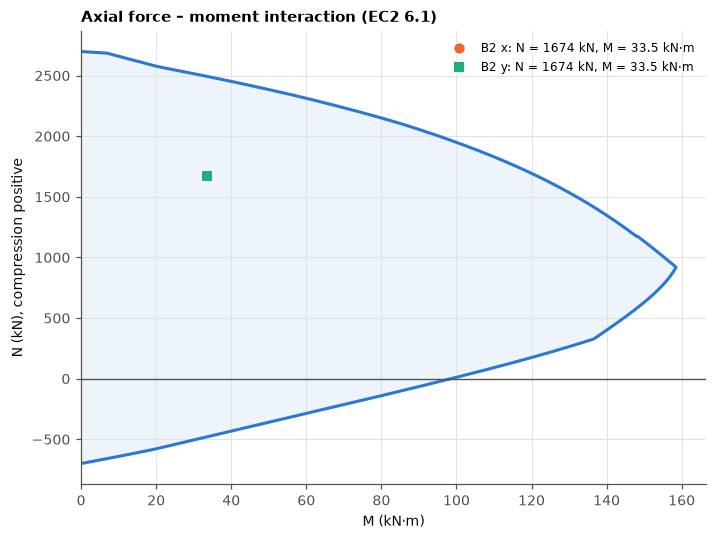

### Biaxial check

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 5.8.9(4) | $N_{Rd} = \dfrac{A_{c}\,f_{cd} + A_{s}\,f_{yd}}{1000}$<br>$\quad = \dfrac{122500\times 17 + 1608.5\times 434.8}{1000}$ | $\mathbf{N_{Rd} = 2781.8}$ kN |
|  | $r_{N} = \dfrac{N_{Ed}}{N_{Rd}}$<br>$\quad = \dfrac{1674.2}{2781.8}$ | $\mathbf{r_{N} = 0.602}$ |
| EC2 5.8.9(4) | Interpolated exponent: $a$ | $a = 1.418$  |
| EC2 Exp. (5.39) | Both moments together (conservative: imperfection and minimum eccentricity in both directions)<br>$U_{bi} = \left(\dfrac{M_{Ed,x}}{M_{Rd}}\right)^{a} + \left(\dfrac{M_{Ed,y}}{M_{Rd}}\right)^{a}$<br>$\quad = \left(\dfrac{33.48}{121.3}\right)^{1.418} + \left(\dfrac{33.48}{121.3}\right)^{1.418}$ | $\mathbf{U_{bi} = 0.322}$ |
| EC2 5.8.9 | **Check:** biaxial bending<br>$U_{bi} = 0.322 \le 1$  | ✅ **PASS**<br>ratio 0.32 |


### Fire resistance (tabulated method A)

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Axis distance: $a_{prov}$ | $a_{prov} = 41$ mm |
| EN 1992-1-2 Table 5.2a, 2.4.2(3) Note 2 | R 60, μ_fi = 0.7 (safe simplification), tabulated width 350 mm: $a_{req}$ | $a_{req} = 40$ mm |
| EN 1992-1-2 5.3.2 | **Check:** fire – axis distance<br>$a_{prov} = 41 \ge a_{req} = 40$ mm | ✅ **PASS**<br>ratio 0.98 |
| EN 1992-1-2 5.3.2(2) Note 2 | Effective length in fire: $l_{0,fi}$ | $l_{0,fi} = 1.75$ m |
| EN 1992-1-2 5.3.2(2) | **Check:** fire – method A effective length limit (m)<br>$l_{0,fi} = 1.75 \le 3$ m | ✅ **PASS**<br>ratio 0.58 |
| EN 1992-1-2 5.3.2(2) Note 3 | First-order eccentricity: $e_{fi}$ | $e_{fi} = 15.27$ mm |
| EN 1992-1-2 5.3.2(2) Note 1 | $e_{max} = 0.15\,h$<br>$\quad = 0.15\times 350$ | $\mathbf{e_{max} = 52.5}$ mm |
| EN 1992-1-2 5.3.2(2) | **Check:** fire – method A eccentricity limit<br>$e_{fi} = 15.27 \le e_{max} = 52.5$ mm | ✅ **PASS**<br>ratio 0.29 |
|  | As / Ac: $\rho_{s}$ | $\rho_{s} = 0.01313$  |
| EN 1992-1-2 5.3.2(2) | **Check:** fire – method A steel limit<br>$\rho_{s} = 0.01313 \le 0.04$  | ✅ **PASS**<br>ratio 0.33 |


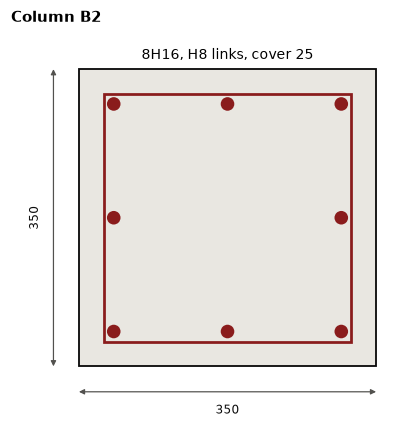

### Summary of checks

| Check | Reference | Ratio | Result |
|:--|:--|:-:|:--|
| nominal cover | EC2 4.4.1 | 1.00 | ✅ PASS |
| minimum bar diameter | EC2 9.5.2(1) | 0.75 | ✅ PASS |
| minimum steel | EC2 9.5.2(2) | 0.24 | ✅ PASS |
| maximum steel | EC2 9.5.2(3) | 0.33 | ✅ PASS |
| link diameter | EC2 9.5.3(1) | 0.75 | ✅ PASS |
| link spacing | EC2 9.5.3(3) | 0.94 | ✅ PASS |
| bar within 150 mm of a restrained bar, else add cross-ties | EC2 9.5.3(6) | 0.89 | ✅ PASS |
| bending + axial, direction x | EC2 6.1 | 0.28 | ✅ PASS |
| bending + axial, direction y | EC2 6.1 | 0.28 | ✅ PASS |
| biaxial bending | EC2 5.8.9 | 0.32 | ✅ PASS |
| fire – axis distance | EN 1992-1-2 5.3.2 | 0.98 | ✅ PASS |
| fire – method A effective length limit (m) | EN 1992-1-2 5.3.2(2) | 0.58 | ✅ PASS |
| fire – method A eccentricity limit | EN 1992-1-2 5.3.2(2) | 0.29 | ✅ PASS |
| fire – method A steel limit | EN 1992-1-2 5.3.2(2) | 0.33 | ✅ PASS |

**All checks pass.**

In [4]:
t = PJ.takedown("B2"); N = 1.35 * t["G"] + 1.5 * t["Q"]; qp = (t["G"] + PSI[BRIEF["category"]][2] * t["Q"]) / N
s = Sheet("Column B2", element="Column B2, ground storey")
D.materials(s, BRIEF["fck"], BRIEF["fyk"], BRIEF["ndp"]); c, cur = section(s, N); As = s["A_s"]
Mx = direction(s, "bending with Beam B", N, PJ.column_joint("B", 1)["M"], 2 * kbeam("B"), b, h, As, qp); M02x = s["M_02"]; s.show("Direction x (Beam B)")
My = direction(s, "bending with Beam 2", N, PJ.column_joint("2", 1)["M"], 2 * kbeam("2"), b, h, As, qp); s.show("Direction y (Beam 2)")
MR = C.MRd(cur, N)
s.let("M_Ed_x", Mx, "kN·m"); s.let("M_Ed_y", My, "kN·m"); s.let("M_Rd", MR, "kN·m", "Moment resistance at N_Ed, from the interaction diagram (same in both directions)", "EC2 6.1"); s.check("M_Ed_x", "<=", "M_Rd", "bending + axial, direction x", "EC2 6.1"); s.check("M_Ed_y", "<=", "M_Rd", "bending + axial, direction y", "EC2 6.1"); s.show("Section check")
P.interaction_plot(cur, [("B2 x", N, Mx), ("B2 y", N, My)])
s.calc("N_Rd", "(A_c*f_cd + A_s*f_yd)/1000", "kN", "EC2 5.8.9(4)"); s.calc("r_N", "N_Ed/N_Rd"); s.let("a", C.biaxial_exponent(s["r_N"]), "", "Interpolated exponent", "EC2 5.8.9(4)"); s.calc("U_bi", "(M_Ed_x/M_Rd)**a + (M_Ed_y/M_Rd)**a", "", "EC2 Exp. (5.39)", "Both moments together (conservative: imperfection and minimum eccentricity in both directions)"); s.check("U_bi", "<=", 1.0, "biaxial bending", "EC2 5.8.9"); s.show("Biaxial check")
D.fire_column(s, BRIEF["fire"], b, s["d_c"], 8, 0.5 * BRIEF["storey"], M02x / N * 1e3, h, As / (b * h))
P.column_section(b, h, c, link, (3, 3), phi, "Column B2"); s.summary()

## Column B1 (edge): large moment, two axial loads checked

A larger axial load **helps** below the balance point, so the column is also checked with the minimum axial load (γ<sub>G,inf</sub> = 1.0, no variable load: EN 1990 Table A1.2(B)) together with the full moment.

## Column B1

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Column B1, ground storey

### Durability – nominal cover

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Main bar diameter: $\phi$ | $\phi = 16$ mm |
| EC2 Table 4.1, 4.4N | Exposure XC1, class S4: $c_{min,dur}$ | $c_{min,dur} = 15$ mm |
| EC2 4.4.1.3(1) | Allowance for deviation: $\Delta c_{dev}$ | $\Delta c_{dev} = 10$ mm |
|  | Link diameter: $\phi_{link}$ | $\phi_{link} = 8$ mm |
| EC2 Exp. (4.1), (4.2) | To the link<br>$c_{nom,link} = \max\left\{\phi_{link};\; c_{min,dur};\; 10\right\} + \Delta c_{dev}$<br>$\quad = \max\left\{8;\; 15;\; 10\right\} + 10$ | $\mathbf{c_{nom,link} = 25}$ mm |
| EC2 Exp. (4.1), (4.2) | To the link, so that the main bar complies<br>$c_{nom,bar} = \max\left\{\phi;\; c_{min,dur};\; 10\right\} + \Delta c_{dev} - \phi_{link}$<br>$\quad = \max\left\{16;\; 15;\; 10\right\} + 10 - 8$ | $\mathbf{c_{nom,bar} = 18}$ mm |
|  | $c_{req} = \max\left\{c_{nom,link};\; c_{nom,bar}\right\}$<br>$\quad = \max\left\{25;\; 18\right\}$ | $\mathbf{c_{req} = 25}$ mm |
|  | Cover adopted: $c_{nom}$ | $c_{nom} = 25$ mm |
| EC2 4.4.1 | **Check:** nominal cover<br>$c_{nom} = 25 \ge c_{req} = 25$ mm | ✅ **PASS**<br>ratio 1.00 |
| NA to EC2, 4.4.1.2(5) | UK projects: confirm concrete quality and cover against BS 8500-1 Tables A.4/A.5 as the UK NA requires. |  |


### Reinforcement

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $N_{Ed}$ | $N_{Ed} = 827.7$ kN |
|  | $A_{c}$ | $A_{c} = 122500$ mm² |
| EC2 9.5.2(1), NA | Minimum bar: $\phi_{min}$ | $\phi_{min} = 12$ mm |
| EC2 9.5.2(1) | **Check:** minimum bar diameter<br>$\phi = 16 \ge \phi_{min} = 12$ mm | ✅ **PASS**<br>ratio 0.75 |
| EC2 Exp. (9.12N) | $A_{s,min} = \max\left\{\dfrac{0.1\,N_{Ed}\times 1000}{f_{yd}};\; 0.002\,A_{c}\right\}$<br>$\quad = \max\left\{\dfrac{0.1\times 827.7\times 1000}{434.8};\; 0.002\times 122500\right\}$ | $\mathbf{A_{s,min} = 245}$ mm² |
| EC2 9.5.2(3) | $A_{s,max} = 0.04\,A_{c}$<br>$\quad = 0.04\times 122500$ | $\mathbf{A_{s,max} = 4900}$ mm² |
|  | 8H16: one at each corner, one at the middle of each face<br>$A_{s} = \dfrac{8\,\pi\,\phi^{2}}{4}$<br>$\quad = \dfrac{8\times \pi\times 16^{2}}{4}$ | $\mathbf{A_{s} = 1608.5}$ mm² |
| EC2 9.5.2(2) | **Check:** minimum steel<br>$A_{s} = 1608.5 \ge A_{s,min} = 245$ mm² | ✅ **PASS**<br>ratio 0.15 |
| EC2 9.5.2(3) | **Check:** maximum steel<br>$A_{s} = 1608.5 \le A_{s,max} = 4900$ mm² | ✅ **PASS**<br>ratio 0.33 |
|  | Bar centre from the face<br>$d_{c} = c_{nom} + \phi_{link} + \dfrac{\phi}{2}$<br>$\quad = 25 + 8 + \dfrac{16}{2}$ | $\mathbf{d_{c} = 41}$ mm |


### Links

| Reference | Calculation | Output |
|:--|:--|:--|
| EC2 9.5.3(1) | $\phi_{link,min} = \max\left\{6;\; \dfrac{16}{4}\right\}$<br>$\quad = \max\left\{6;\; \dfrac{16}{4}\right\}$ | $\mathbf{\phi_{link,min} = 6}$ mm |
| EC2 9.5.3(1) | **Check:** link diameter<br>$\phi_{link} = 8 \ge \phi_{link,min} = 6$ mm | ✅ **PASS**<br>ratio 0.75 |
| EC2 9.5.3(3), NA | min(20 φ_min, smaller side, 400): $s_{cl,max}$ | $s_{cl,max} = 320$ mm |
|  | Link spacing: $s_{link}$ | $s_{link} = 300$ mm |
| EC2 9.5.3(3) | **Check:** link spacing<br>$s_{link} = 300 \le s_{cl,max} = 320$ mm | ✅ **PASS**<br>ratio 0.94 |
| EC2 9.5.3(4) | Within 350 mm above/below a beam or slab, and at laps of bars > 14 mm<br>$s_{cl,red} = 0.6\,s_{cl,max}$<br>$\quad = 0.6\times 320$ | $\mathbf{s_{cl,red} = 192}$ mm |
|  | **PROVIDE: H8 links @ 300 mm; @ 175 mm near beams, slabs and laps** | 🟦 **H8 links @ 300 mm; @ 175 mm near beams, slabs and laps** |
|  | Distance from an intermediate bar to the restrained corner bar (centres): $s_{face}$ | $s_{face} = 134$ mm |
| EC2 9.5.3(6) | **Check:** bar within 150 mm of a restrained bar, else add cross-ties<br>$s_{face} = 134 \le 150$ mm | ✅ **PASS**<br>ratio 0.89 |


### Direction x (Beam B, large moment)

| Reference | Calculation | Output |
|:--|:--|:--|
| BS 8110-1 3.2.1.2.5 | First-order moment at the top, bending with Beam B: $M_{top}$ | $M_{top} = 49.28$ kN·m |
|  | I/l of each column: $k_{c}$ | $k_{c} = 357.3$ 10³ mm³ |
|  | Sum of I/l of the beams (rectangular gross section, conservative): $k_{b}$ | $k_{b} = 520.8$ 10³ mm³ |
| EC2 5.8.3.2(3), (4) | Top: columns above and below, beams at 2EI/l<br>$k_{1} = \max\left\{\dfrac{2\,k_{c}}{2\,k_{b}};\; 0.1\right\}$<br>$\quad = \max\left\{\dfrac{2\times 357.3}{2\times 520.8};\; 0.1\right\}$ | $\mathbf{k_{1} = 0.686}$ |
|  | Clear height: $l$ | $l = 3$ m |
| EC2 Exp. (5.15), k₂ = ∞ | Base taken as pinned (upper bound: the bracket tends to 2)<br>$l_{0} = 0.5\,l\,\sqrt{\left(1 + \dfrac{k_{1}}{0.45 + k_{1}}\right)\times 2}$<br>$\quad = 0.5\times 3\times \sqrt{\left(1 + \dfrac{0.686}{0.45 + 0.686}\right)\times 2}$ | $\mathbf{l_{0} = 2.687}$ m |
|  | $h$ | $h = 350$ mm |
|  | $b$ | $b = 350$ mm |
| EC2 5.2(7), 5.2(9) – braced | Imperfection eccentricity<br>$e_{i} = \dfrac{l_{0}\times 1000}{400}$<br>$\quad = \dfrac{2.687\times 1000}{400}$ | $\mathbf{e_{i} = 6.716}$ mm |
| EC2 6.1(4) | Minimum eccentricity<br>$e_{0} = \max\left\{\dfrac{h}{30};\; 20\right\}$<br>$\quad = \max\left\{\dfrac{350}{30};\; 20\right\}$ | $\mathbf{e_{0} = 20}$ mm |
| EC2 6.1(4) | $M_{min} = \dfrac{N_{Ed}\,e_{0}}{1000}$<br>$\quad = \dfrac{827.7\times 20}{1000}$ | $\mathbf{M_{min} = 16.55}$ kN·m |
| EC2 5.2(7) | Larger end, with imperfection<br>$M_{02} = M_{top} + \dfrac{N_{Ed}\,e_{i}}{1000}$<br>$\quad = 49.28 + \dfrac{827.7\times 6.716}{1000}$ | $\mathbf{M_{02} = 54.84}$ kN·m |
| EC2 5.2(7) | Smaller end: pinned base, imperfection only<br>$M_{01} = \dfrac{N_{Ed}\,e_{i}}{1000}$<br>$\quad = \dfrac{827.7\times 6.716}{1000}$ | $\mathbf{M_{01} = 5.559}$ kN·m |
| EC2 5.8.3.2(1) | Radius of gyration, rectangle<br>$i = \dfrac{h}{\sqrt{12}}$<br>$\quad = \dfrac{350}{\sqrt{12}}$ | $\mathbf{i = 101}$ mm |
| EC2 Exp. (5.14) | $\lambda = \dfrac{l_{0}\times 1000}{i}$<br>$\quad = \dfrac{2.687\times 1000}{101}$ | $\mathbf{\lambda = 26.59}$ |
| EC2 5.8.3.1 | $n = \dfrac{N_{Ed}\times 1000}{b\,h\,f_{cd}}$<br>$\quad = \dfrac{827.7\times 1000}{350\times 350\times 17}$ | $\mathbf{n = 0.397}$ |
| EC2 5.8.3.1(1) | Creep ratio not used: default: $A$ | $A = 0.7$  |
| EC2 5.8.3.1(1) | $\omega = \dfrac{A_{s}\,f_{yd}}{b\,h\,f_{cd}}$<br>$\quad = \dfrac{1608.5\times 434.8}{350\times 350\times 17}$ | $\mathbf{\omega = 0.336}$ |
| EC2 5.8.3.1(1) | $B = \sqrt{1 + 2\,\omega}$<br>$\quad = \sqrt{1 + 2\times 0.336}$ | $\mathbf{B = 1.293}$ |
| EC2 5.8.3.1(1) | $r_{m} = \dfrac{M_{01}}{M_{02}}$<br>$\quad = \dfrac{5.559}{54.84}$ | $\mathbf{r_{m} = 0.101}$ |
| EC2 5.8.3.1(1) | $C = 1.7 - r_{m}$<br>$\quad = 1.7 - 0.101$ | $\mathbf{C = 1.599}$ |
| EC2 Exp. (5.13N), NA | $\lambda_{lim} = \dfrac{20\,A\,B\,C}{\sqrt{n}}$<br>$\quad = \dfrac{20\times 0.7\times 1.293\times 1.599}{\sqrt{0.397}}$ | $\mathbf{\lambda_{lim} = 45.9}$ |
| EC2 5.8.3.1 | λ ≤ λ<sub>lim</sub> → the column is **STOCKY (short)** : second-order effects may be ignored. |  |
| EC2 5.8.8.1, 6.1(4) | Design moment, bending with Beam B<br>$M_{Ed} = \max\left\{M_{02};\; M_{min}\right\}$<br>$\quad = \max\left\{54.84;\; 16.55\right\}$ | $\mathbf{M_{Ed} = 54.84}$ kN·m |


### Direction y (Beam 1)

| Reference | Calculation | Output |
|:--|:--|:--|
| BS 8110-1 3.2.1.2.5 | First-order moment at the top, bending with Beam 1: $M_{top}$ | $M_{top} = 3.128$ kN·m |
|  | Sum of I/l of the beams (rectangular gross section, conservative): $k_{b}$ | $k_{b} = 1250$ 10³ mm³ |
| EC2 5.8.3.2(3), (4) | Top: columns above and below, beams at 2EI/l<br>$k_{1} = \max\left\{\dfrac{2\,k_{c}}{2\,k_{b}};\; 0.1\right\}$<br>$\quad = \max\left\{\dfrac{2\times 357.3}{2\times 1250};\; 0.1\right\}$ | $\mathbf{k_{1} = 0.286}$ |
| EC2 Exp. (5.15), k₂ = ∞ | Base taken as pinned (upper bound: the bracket tends to 2)<br>$l_{0} = 0.5\,l\,\sqrt{\left(1 + \dfrac{k_{1}}{0.45 + k_{1}}\right)\times 2}$<br>$\quad = 0.5\times 3\times \sqrt{\left(1 + \dfrac{0.286}{0.45 + 0.286}\right)\times 2}$ | $\mathbf{l_{0} = 2.5}$ m |
| EC2 5.2(7), 5.2(9) – braced | Imperfection eccentricity<br>$e_{i} = \dfrac{l_{0}\times 1000}{400}$<br>$\quad = \dfrac{2.5\times 1000}{400}$ | $\mathbf{e_{i} = 6.249}$ mm |
| EC2 5.2(7) | Larger end, with imperfection<br>$M_{02} = M_{top} + \dfrac{N_{Ed}\,e_{i}}{1000}$<br>$\quad = 3.128 + \dfrac{827.7\times 6.249}{1000}$ | $\mathbf{M_{02} = 8.3}$ kN·m |
| EC2 5.2(7) | Smaller end: pinned base, imperfection only<br>$M_{01} = \dfrac{N_{Ed}\,e_{i}}{1000}$<br>$\quad = \dfrac{827.7\times 6.249}{1000}$ | $\mathbf{M_{01} = 5.172}$ kN·m |
| EC2 Exp. (5.14) | $\lambda = \dfrac{l_{0}\times 1000}{i}$<br>$\quad = \dfrac{2.5\times 1000}{101}$ | $\mathbf{\lambda = 24.74}$ |
| EC2 5.8.3.1(1) | $r_{m} = \dfrac{M_{01}}{M_{02}}$<br>$\quad = \dfrac{5.172}{8.3}$ | $\mathbf{r_{m} = 0.623}$ |
| EC2 5.8.3.1(1) | $C = 1.7 - r_{m}$<br>$\quad = 1.7 - 0.623$ | $\mathbf{C = 1.077}$ |
| EC2 Exp. (5.13N), NA | $\lambda_{lim} = \dfrac{20\,A\,B\,C}{\sqrt{n}}$<br>$\quad = \dfrac{20\times 0.7\times 1.293\times 1.077}{\sqrt{0.397}}$ | $\mathbf{\lambda_{lim} = 30.92}$ |
| EC2 5.8.3.1 | λ ≤ λ<sub>lim</sub> → the column is **STOCKY (short)** : second-order effects may be ignored. |  |
| EC2 5.8.8.1, 6.1(4) | Design moment, bending with Beam 1<br>$M_{Ed} = \max\left\{M_{02};\; M_{min}\right\}$<br>$\quad = \max\left\{8.3;\; 16.55\right\}$ | $\mathbf{M_{Ed} = 16.55}$ kN·m |


### Section check

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $M_{Ed,x}$ | $M_{Ed,x} = 54.84$ kN·m |
|  | $M_{Ed,y}$ | $M_{Ed,y} = 16.55$ kN·m |
| EC2 6.1 | At N_Ed: $M_{Rd}$ | $M_{Rd} = 156.5$ kN·m |
| EC2 6.1 | **Check:** bending + axial, direction x<br>$M_{Ed,x} = 54.84 \le M_{Rd} = 156.5$ kN·m | ✅ **PASS**<br>ratio 0.35 |
|  | Minimum axial load: $N_{min}$ | $N_{min} = 449.5$ kN |
| EC2 6.1 | At N_min: $M_{Rd,min}$ | $M_{Rd,min} = 142.3$ kN·m |
| EC2 6.1 | **Check:** bending with minimum axial load<br>$M_{Ed,x} = 54.84 \le M_{Rd,min} = 142.3$ kN·m | ✅ **PASS**<br>ratio 0.39 |
| EC2 5.8.9(4) | $N_{Rd} = \dfrac{A_{c}\,f_{cd} + A_{s}\,f_{yd}}{1000}$<br>$\quad = \dfrac{122500\times 17 + 1608.5\times 434.8}{1000}$ | $\mathbf{N_{Rd} = 2781.8}$ kN |
|  | $r_{N} = \dfrac{N_{Ed}}{N_{Rd}}$<br>$\quad = \dfrac{827.7}{2781.8}$ | $\mathbf{r_{N} = 0.298}$ |
| EC2 5.8.9(4) | Interpolated exponent: $a$ | $a = 1.165$  |
| EC2 Exp. (5.39) | $U_{bi} = \left(\dfrac{M_{Ed,x}}{M_{Rd}}\right)^{a} + \left(\dfrac{M_{Ed,y}}{M_{Rd}}\right)^{a}$<br>$\quad = \left(\dfrac{54.84}{156.5}\right)^{1.165} + \left(\dfrac{16.55}{156.5}\right)^{1.165}$ | $\mathbf{U_{bi} = 0.368}$ |
| EC2 5.8.9 | **Check:** biaxial bending<br>$U_{bi} = 0.368 \le 1$  | ✅ **PASS**<br>ratio 0.37 |


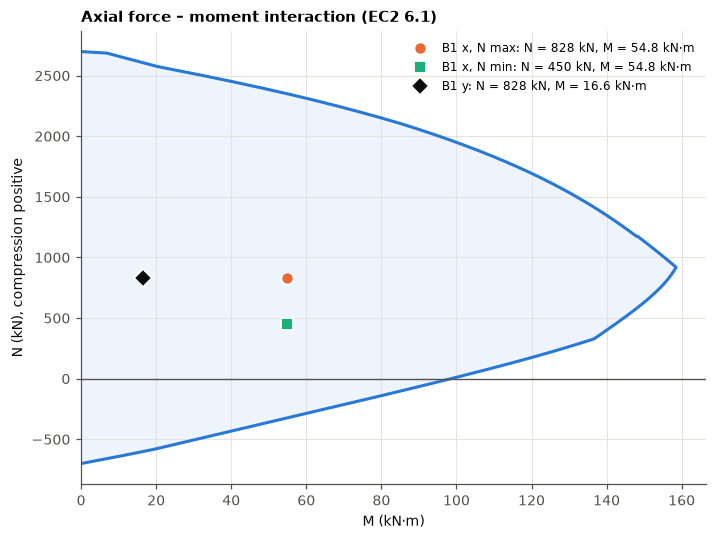

### Fire resistance (tabulated method B)

| Reference | Calculation | Output |
|:--|:--|:--|
| EN 1992-1-2 5.3.3(3) Note 1 | $N_{0,fi} = 0.7\,N_{Ed}$<br>$\quad = 0.7\times 827.7$ | $\mathbf{N_{0,fi} = 579.4}$ kN |
| EN 1992-1-2 Exp. (5.8a) | $n_{fi} = \dfrac{N_{0,fi}\times 1000}{0.7\,\left(A_{c}\,f_{cd} + A_{s}\,f_{yd}\right)}$<br>$\quad = \dfrac{579.4\times 1000}{0.7\times \left(122500\times 17 + 1608.5\times 434.8\right)}$ | $\mathbf{n_{fi} = 0.298}$ |
| EN 1992-1-2 5.3.3(2) | $\omega = \dfrac{A_{s}\,f_{yd}}{A_{c}\,f_{cd}}$<br>$\quad = \dfrac{1608.5\times 434.8}{122500\times 17}$ | $\mathbf{\omega = 0.336}$ |
| EN 1992-1-2 Table 5.2b | **Check:** fire – tabulated row ω = 0.1 is conservative<br>$\omega = 0.336 \ge 0.1$  | ✅ **PASS**<br>ratio 0.30 |
|  | First-order eccentricity: $e_{fi}$ | $e_{fi} = 66.26$ mm |
| EN 1992-1-2 5.3.3(2) | min(0.25b, 100): $e_{max}$ | $e_{max} = 87.5$ mm |
| EN 1992-1-2 5.3.3(2) | **Check:** fire – method B eccentricity limit<br>$e_{fi} = 66.26 \le e_{max} = 87.5$ mm | ✅ **PASS**<br>ratio 0.76 |
| EN 1992-1-2 5.3.3(3) Note 2 | 0.5 × storey height: $l_{0,fi}$ | $l_{0,fi} = 1.75$ m |
| EN 1992-1-2 Exp. (5.8c) | $\lambda_{fi} = \dfrac{l_{0,fi}\times 1000}{i}$<br>$\quad = \dfrac{1.75\times 1000}{101}$ | $\mathbf{\lambda_{fi} = 17.32}$ |
| EN 1992-1-2 5.3.3(2) | **Check:** fire – method B slenderness limit<br>$\lambda_{fi} = 17.32 \le 30$  | ✅ **PASS**<br>ratio 0.58 |
| EN 1992-1-2 Table 5.2b | R 60, column n = 0.3, tabulated width 300 mm: $a_{req}$ | $a_{req} = 25$ mm |
|  | Axis distance: $a_{prov}$ | $a_{prov} = 41$ mm |
| EN 1992-1-2 5.3.3 | **Check:** fire – axis distance<br>$a_{prov} = 41 \ge a_{req} = 25$ mm | ✅ **PASS**<br>ratio 0.61 |


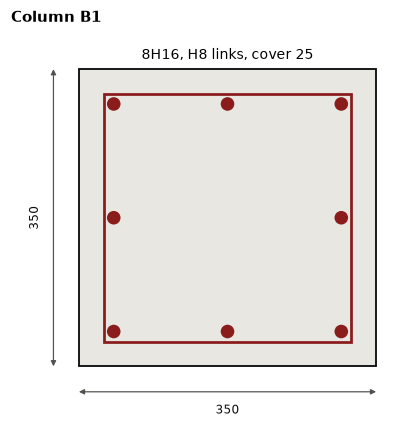

### Summary of checks

| Check | Reference | Ratio | Result |
|:--|:--|:-:|:--|
| nominal cover | EC2 4.4.1 | 1.00 | ✅ PASS |
| minimum bar diameter | EC2 9.5.2(1) | 0.75 | ✅ PASS |
| minimum steel | EC2 9.5.2(2) | 0.15 | ✅ PASS |
| maximum steel | EC2 9.5.2(3) | 0.33 | ✅ PASS |
| link diameter | EC2 9.5.3(1) | 0.75 | ✅ PASS |
| link spacing | EC2 9.5.3(3) | 0.94 | ✅ PASS |
| bar within 150 mm of a restrained bar, else add cross-ties | EC2 9.5.3(6) | 0.89 | ✅ PASS |
| bending + axial, direction x | EC2 6.1 | 0.35 | ✅ PASS |
| bending with minimum axial load | EC2 6.1 | 0.39 | ✅ PASS |
| biaxial bending | EC2 5.8.9 | 0.37 | ✅ PASS |
| fire – tabulated row ω = 0.1 is conservative | EN 1992-1-2 Table 5.2b | 0.30 | ✅ PASS |
| fire – method B eccentricity limit | EN 1992-1-2 5.3.3(2) | 0.76 | ✅ PASS |
| fire – method B slenderness limit | EN 1992-1-2 5.3.3(2) | 0.58 | ✅ PASS |
| fire – axis distance | EN 1992-1-2 5.3.3 | 0.61 | ✅ PASS |

**All checks pass.**

In [5]:
t = PJ.takedown("B1"); N = 1.35 * t["G"] + 1.5 * t["Q"]; qp = (t["G"] + PSI[BRIEF["category"]][2] * t["Q"]) / N; Nmin = t["G"]
s = Sheet("Column B1", element="Column B1, ground storey")
D.materials(s, BRIEF["fck"], BRIEF["fyk"], BRIEF["ndp"], show=False); s.rows = []; c, cur = section(s, N); As = s["A_s"]
Mx = direction(s, "bending with Beam B", N, PJ.column_joint("B", 0)["M"], kbeam("B"), b, h, As, qp); M02x = s["M_02"]; s.show("Direction x (Beam B, large moment)")
My = direction(s, "bending with Beam 1", N, PJ.column_joint("1", 1)["M"], 2 * kbeam("1"), b, h, As, qp); s.show("Direction y (Beam 1)")
s.let("M_Ed_x", Mx, "kN·m"); s.let("M_Ed_y", My, "kN·m"); s.let("M_Rd", C.MRd(cur, N), "kN·m", "At N_Ed", "EC2 6.1"); s.check("M_Ed_x", "<=", "M_Rd", "bending + axial, direction x", "EC2 6.1")
s.let("N_min", Nmin, "kN", "Minimum axial load"); s.let("M_Rd_min", C.MRd(cur, Nmin), "kN·m", "At N_min", "EC2 6.1"); s.check("M_Ed_x", "<=", "M_Rd_min", "bending with minimum axial load", "EC2 6.1")
s.calc("N_Rd", "(A_c*f_cd + A_s*f_yd)/1000", "kN", "EC2 5.8.9(4)"); s.calc("r_N", "N_Ed/N_Rd"); s.let("a", C.biaxial_exponent(s["r_N"]), "", "Interpolated exponent", "EC2 5.8.9(4)"); s.calc("U_bi", "(M_Ed_x/M_Rd)**a + (M_Ed_y/M_Rd)**a", "", "EC2 Exp. (5.39)"); s.check("U_bi", "<=", 1.0, "biaxial bending", "EC2 5.8.9"); s.show("Section check")
P.interaction_plot(cur, [("B1 x, N max", N, Mx), ("B1 x, N min", Nmin, Mx), ("B1 y", N, My)])
D.fire_column_b(s, BRIEF["fire"], b, s["d_c"], N, As, b * h, 0.5 * BRIEF["storey"], h / math.sqrt(12), M02x / N * 1e3)
P.column_section(b, h, c, link, (3, 3), phi, "Column B1"); s.summary()